In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("abdullahiyunus/nigeria-houses-and-prices-dataset")

print("Path to dataset files:", path)

100%|██████████| 157k/157k [00:00<00:00, 47.8MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/abdullahiyunus/nigeria-houses-and-prices-dataset/versions/1


In [3]:
df = pd.read_csv(path + "/nigeria_houses_data.csv")
df.head()

,bedrooms,bathrooms,toilets,parking_space,title,town,state,price
0,6.0,5.0,5.0,4.0,Detached Duplex,Mabushi,Abuja,450000000.0
1,4.0,5.0,5.0,4.0,Terraced Duplexes,Katampe,Abuja,800000000.0
2,4.0,5.0,5.0,4.0,Detached Duplex,Lekki,Lagos,120000000.0
3,4.0,4.0,5.0,6.0,Detached Duplex,Ajah,Lagos,40000000.0
4,4.0,4.0,5.0,2.0,Semi Detached Duplex,Lekki,Lagos,75000000.0


In [4]:
# check unique values for the dataset
df.nunique()

,0
bedrooms,9
bathrooms,9
toilets,9
parking_space,9
title,7
town,189
state,25
price,539


In [5]:
for col in df.columns:
  print(col)
  print(df[col].unique())

bedrooms
[6. 4. 5. 2. 1. 3. 8. 9. 7.]
bathrooms
[5. 4. 2. 1. 6. 3. 8. 7. 9.]
toilets
[5. 6. 3. 1. 7. 4. 8. 2. 9.]
parking_space
[4. 6. 2. 1. 5. 3. 8. 7. 9.]
title
['Detached Duplex' 'Terraced Duplexes' 'Semi Detached Duplex'
 'Detached Bungalow' 'Block of Flats' 'Semi Detached Bungalow'
 'Terraced Bungalow']
town
['Mabushi' 'Katampe' 'Lekki' 'Ajah' 'Epe' 'Lokogoma District' 'Oredo'
 'Victoria Island (VI)' 'Mowe Ofada' 'Ikeja' 'Ikoyi' 'Magodo' 'Kaura'
 'Galadimawa' 'Gwarinpa' 'Abeokuta North' 'Lugbe District' 'Ibeju Lekki'
 'Yaba' 'Sango Ota' 'Ifako-Ijaiye' 'Agege' 'Ikorodu' 'Jahi' 'Ibadan'
 'Orozo' 'Ifo' 'Owerri North' 'Guzape District' 'Idu Industrial'
 'Owerri Municipal' 'Isheri North' 'Utako' 'Port Harcourt' 'Kuje' 'Isheri'
 'Life Camp' 'Ipaja' 'Ado-Odo/Ota' 'Dape' 'Mushin' 'Ejigbo' 'Isolo'
 'Ojodu' 'Gaduwa' 'Enugu' 'Dakwo' 'Asokoro District' 'Alimosho' 'Sagamu'
 'Chikun' 'Egbeda' 'Wuye' 'Kubwa' 'Shomolu' 'Ogudu' 'Owerri West' 'Ibafo'
 'Surulere' 'Obio-Akpor' 'Ayobo' 'Apo' 'Mowe Tow

In [6]:
# check  for Nan value
df.isna().sum()

,0
bedrooms,0
bathrooms,0
toilets,0
parking_space,0
title,0
town,0
state,0
price,0


In [7]:
# check the type for each columns
df.dtypes

,0
bedrooms,float64
bathrooms,float64
toilets,float64
parking_space,float64
title,object
town,object
state,object
price,float64


In [8]:
#change object types of columns

df['title'] = df['title'].astype('string')
df['town'] = df['town'].astype('string')
df['state']= df['state'].astype('string')


In [9]:
df.dtypes

,0
bedrooms,float64
bathrooms,float64
toilets,float64
parking_space,float64
title,string[python]
town,string[python]
state,string[python]
price,float64


In [10]:
df.head()

,bedrooms,bathrooms,toilets,parking_space,title,town,state,price
0,6.0,5.0,5.0,4.0,Detached Duplex,Mabushi,Abuja,450000000.0
1,4.0,5.0,5.0,4.0,Terraced Duplexes,Katampe,Abuja,800000000.0
2,4.0,5.0,5.0,4.0,Detached Duplex,Lekki,Lagos,120000000.0
3,4.0,4.0,5.0,6.0,Detached Duplex,Ajah,Lagos,40000000.0
4,4.0,4.0,5.0,2.0,Semi Detached Duplex,Lekki,Lagos,75000000.0


In [41]:
df.

AttributeError: 'DataFrame' object has no attribute 'unique'

In [13]:
#Check for outlier's in the price column using z-score
from scipy import stats
z_scores = np.abs(stats.zscore(df['price']))
threshold = 3
outlier_indices = np.where(z_scores > threshold)[0]
outliers = df.iloc[outlier_indices]

len(outliers.price)




9

In [21]:
outliers

,bedrooms,bathrooms,toilets,parking_space,title,town,state,price
4096,7.0,7.0,8.0,8.0,Detached Duplex,Ikoyi,Lagos,1.800000e+12
4327,5.0,5.0,6.0,4.0,Detached Duplex,Lekki,Lagos,1.600000e+11
6632,4.0,4.0,5.0,4.0,Semi Detached Duplex,Ikoyi,Lagos,4.500000e+11
7098,5.0,5.0,6.0,4.0,Semi Detached Duplex,Lekki,Lagos,1.250000e+11
13490,3.0,3.0,3.0,4.0,Semi Detached Duplex,Ajah,Lagos,4.200000e+10
15806,5.0,5.0,5.0,1.0,Detached Duplex,Ifako-Ijaiye,Lagos,5.500000e+10
15836,5.0,6.0,7.0,4.0,Terraced Duplexes,Guzape District,Abuja,8.500000e+10
15962,9.0,9.0,1.0,4.0,Detached Duplex,Lekki,Lagos,3.500000e+11
17383,4.0,4.0,5.0,3.0,Detached Duplex,Ajah,Lagos,5.000000e+10


/tmp/ipykernel_472/1822291449.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


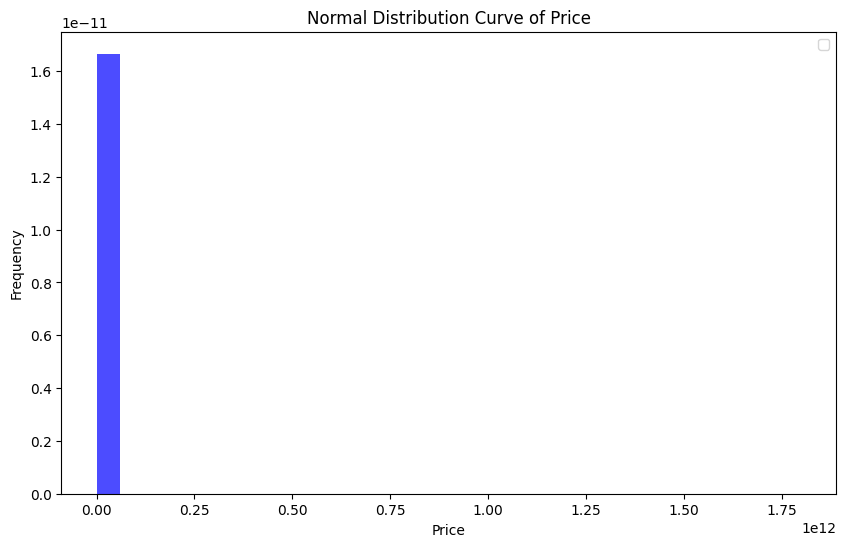

In [15]:
#plot the normal distribution curve of price
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(df['price'], bins=30, density=True, alpha=0.7, color='blue')
plt.axvline(df['price'].mean(), color='red', linestyle='dashed', linewidth=2, label='Mean')
plt.axvline(df['price'].median(), color='green', linestyle='dashed', linewidth=2, label='Median')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.title('Normal Distribution Curve of Price')
plt.legend()
plt.show()


In [22]:
# Calculate 99th percentile of price
price_99 = df['price'].quantile(0.95)
print(f"99th percentile value: {price_99:,.2f}")

# Filter DataFrame to remove outliers above 99th percentile
df_filtered = df[df['price'] <= price_99].copy()
print(f"Original dataset size: {len(df)}")
print(f"Filtered dataset size: {len(df_filtered)}")

# Re-assign df to df_filtered if you want to apply changes to df
df = df_filtered
df1 = df

99th percentile value: 330,000,000.00
Original dataset size: 22961
Filtered dataset size: 21863


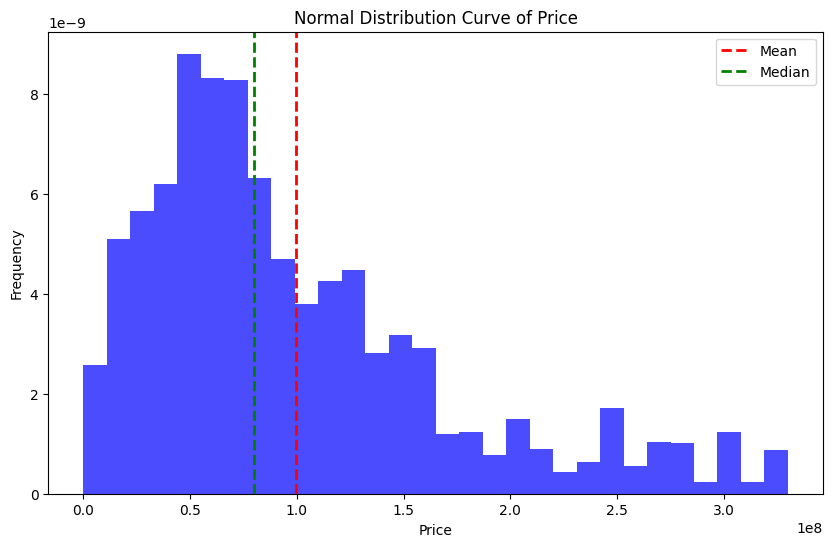

In [24]:
#lets do the normal distribution again
plt.figure(figsize=(10, 6))
plt.hist(df_filtered['price'], bins=30, density=True, alpha=0.7, color='blue')
plt.axvline(df1['price'].mean(), color='red', linestyle='dashed', linewidth=2, label='Mean')
plt.axvline(df_filtered['price'].median(), color='green', linestyle='dashed', linewidth=2, label='Median')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.title('Normal Distribution Curve of Price')
plt.legend()
plt.show()

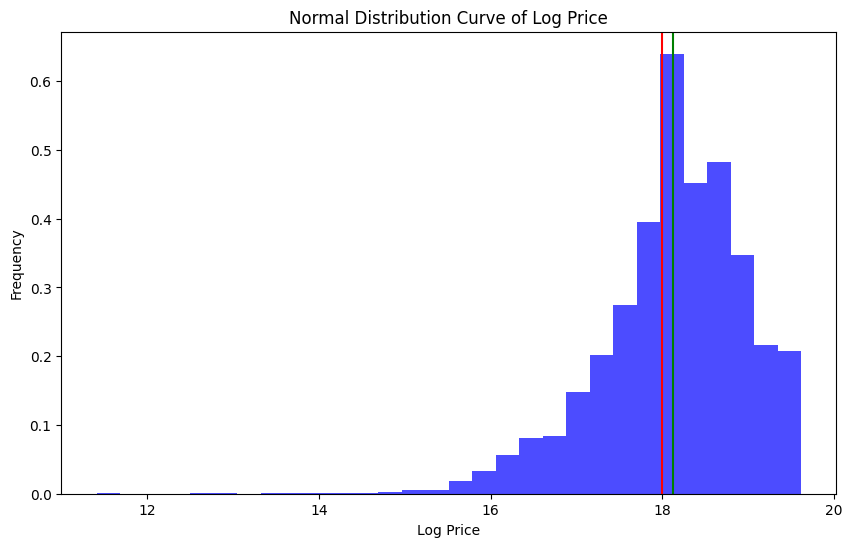

In [28]:
#let's apply log normal
df1['log_price'] = np.log(df1['price'])

# ploting the graph
plt.figure(figsize=(10, 6))
plt.hist(df1['log_price'], bins = 30, density = True, alpha = 0.7, color = 'blue')
plt.axvline(df1['log_price'].mean(), color = 'green')
plt.axvline(df1['log_price'].mode()[0], color = 'red')
plt.xlabel('Log Price')
plt.ylabel('Frequency')
plt.title('Normal Distribution Curve of Log Price')
plt.show()

Why the Chart Looks the Way It Does:
The Sharp Cutoff on the Right (at ~20.0): You will notice the distribution suddenly stops with a flat wall right around $20.0$$20.0$ on the x-axis.

This is because in cell c29bff84, I filtered the dataset to remove everything above the 95th percentile ($500,000,000$$500,000,000$ Naira).
Mathematically, $\ln(500,000,000) \approx 20.03$$\ln(500,000,000) \approx 20.03$.
By removing those outliers before taking the log, I created an artificial cliff edge on the right side of what would otherwise be a beautifully symmetric, bell-shaped normal curve.
The Left-Hand Tail: The long tail extending to the left (down to $11.0$$11.0$ or $12.0$$12.0$, which is about $60,000$$60,000$ to $160,000$$160,000$ Naira) represents very cheap listings or potential data entry errors on the low end.

Takeaway:
If you want to train your model using Log-Target Regression (which is highly recommended for housing prices),we actually do not need to remove the 95th percentile outliers beforehand. The logarithmic scale naturally compresses the distance of extreme values, meaning the model can easily handle those high-end prices without being skewed!

**ONE HOT ENCODING **OF THE STRING TYPE COLUMNS

In [29]:
#getting the dummy variables for title,town state
df_encoded = pd.get_dummies(df1, columns=['title','town','state'])
df_encoded.head()


,bedrooms,bathrooms,toilets,parking_space,price,log_price,title_Block of Flats,title_Detached Bungalow,title_Detached Duplex,title_Semi Detached Bungalow,...,state_Kogi,state_Kwara,state_Lagos,state_Nasarawa,state_Niger,state_Ogun,state_Osun,state_Oyo,state_Plateau,state_Rivers
2,4.0,5.0,5.0,4.0,120000000.0,18.603002,False,False,True,False,...,False,False,True,False,False,False,False,False,False,False
3,4.0,4.0,5.0,6.0,40000000.0,17.504390,False,False,True,False,...,False,False,True,False,False,False,False,False,False,False
4,4.0,4.0,5.0,2.0,75000000.0,18.132999,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
6,4.0,5.0,5.0,4.0,65000000.0,17.989898,False,False,True,False,...,False,False,True,False,False,False,False,False,False,False
7,2.0,2.0,3.0,6.0,12000000.0,16.300417,False,True,False,False,...,False,False,True,False,False,False,False,False,False,False


In [30]:
df_encoded.drop(['price'], axis=1, inplace=True)
df_encoded.head()

,bedrooms,bathrooms,toilets,parking_space,log_price,title_Block of Flats,title_Detached Bungalow,title_Detached Duplex,title_Semi Detached Bungalow,title_Semi Detached Duplex,...,state_Kogi,state_Kwara,state_Lagos,state_Nasarawa,state_Niger,state_Ogun,state_Osun,state_Oyo,state_Plateau,state_Rivers
2,4.0,5.0,5.0,4.0,18.603002,False,False,True,False,False,...,False,False,True,False,False,False,False,False,False,False
3,4.0,4.0,5.0,6.0,17.504390,False,False,True,False,False,...,False,False,True,False,False,False,False,False,False,False
4,4.0,4.0,5.0,2.0,18.132999,False,False,False,False,True,...,False,False,True,False,False,False,False,False,False,False
6,4.0,5.0,5.0,4.0,17.989898,False,False,True,False,False,...,False,False,True,False,False,False,False,False,False,False
7,2.0,2.0,3.0,6.0,16.300417,False,True,False,False,False,...,False,False,True,False,False,False,False,False,False,False


In [47]:
#now concat to the df
df_final = pd.concat([df, df_onehot], axis=1)
df_final.head()

#drop some columns
df_final.drop(['title', 'town', 'state'], axis=1, inplace=True)
df_final.head()

,bedrooms,bathrooms,toilets,parking_space,price,title_Block of Flats,title_Detached Bungalow,title_Detached Duplex,title_Semi Detached Bungalow,title_Semi Detached Duplex,...,state_Kogi,state_Kwara,state_Lagos,state_Nasarawa,state_Niger,state_Ogun,state_Osun,state_Oyo,state_Plateau,state_Rivers
0,6.0,5.0,5.0,4.0,450000000.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,4.0,5.0,5.0,4.0,800000000.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,4.0,5.0,5.0,4.0,120000000.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,4.0,4.0,5.0,6.0,40000000.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4.0,4.0,5.0,2.0,75000000.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [48]:
Xe= df_final.drop('price', axis=1)
ye= df_final['price']

In [49]:
Xe_train, Xe_test, ye_train, ye_test = train_test_split(Xe, ye, test_size=0.2, random_state=42)

In [50]:
model1 = RandomForestRegressor()
model1.fit(Xe_train, ye_train)

RandomForestRegressor()

In [52]:
#Evaluate the model
from sklearn.metrics import mean_squared_error, r2_score

ye_pred = model1.predict(Xe_test)
mse = mean_squared_error(ye_test, ye_pred)
r2 = r2_score(ye_test, ye_pred)
print("Mean Squared Error:", mse)
print("R-squared score:", r2)

#Accuracy
accuracy = model1.score(Xe_test, ye_test)
print("Accuracy:", accuracy)

Mean Squared Error: 2.730299093916003e+20
R-squared score: -3324.402475655489
Accuracy: -3324.402475655489


In [32]:
X = df_encoded.drop('log_price', axis=1)
y = df_encoded['log_price']

In [33]:
y

,log_price
2,18.603002
3,17.504390
4,18.132999
6,17.989898
7,16.300417
...,...
24321,16.523561
24322,17.034386
24323,18.035018
24324,18.172219


In [34]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [35]:
#Scaling our dataset
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [40]:
X_train_scaled

array([[-0.29629686, -0.51435141, -0.14163559, ..., -0.14188025,
        -0.01013832, -0.13670466],
       [-0.29629686, -0.51435141, -0.14163559, ..., -0.14188025,
        -0.01013832, -0.13670466],
       [-0.29629686, -0.51435141, -0.14163559, ..., -0.14188025,
        -0.01013832, -0.13670466],
       ...,
       [ 0.59049749,  0.35150312,  0.6794036 , ..., -0.14188025,
        -0.01013832, -0.13670466],
       [ 0.59049749,  1.21735766,  0.6794036 , ..., -0.14188025,
        -0.01013832, -0.13670466],
       [-1.18309121, -1.38020594, -0.96267477, ..., -0.14188025,
        -0.01013832, -0.13670466]])

In [41]:
y_train

,price
4058,75000000.0
15290,120000000.0
19500,70000000.0
3461,600000000.0
977,95000000.0
...,...
21575,75000000.0
5390,85000000.0
860,250000000.0
15795,220000000.0


In [ ]:
'SVR': {
        'model' :svm.SVC(),
        'param': {
            'kernel': ['rbf','linear'],
        'C': [1,10,20]}
           },
    'LogisticRegression': {
        'model' :LogisticRegression(solver='liblinear',multi_class='auto'),
        'param': {
        'C': [1,10,20]},
           },
    'RandomForest': {
        'model' :RandomForestClassifier(),
        'param': {

        'n_estimators': [40,30,20]}
    },
# #     'MultinomialNB': {

#         'model' :MultinomialNB(),
#     },
    "DecisionTree":{
        'model' :DecisionTreeClassifier(),
        'param': {
            'max_depth': [5,8,10]
        }
    }
}
scores= []
for model_name, mp in model_chars.items():
    ggs= GridSearchCV(mp['model'], mp['param'], cv=5, return_train_score= False)
    ggs.fit(X_train, y_train)
    scores.append({
        'model': model_name,
        'parameters': ggs.best_params_,
        'best_scores': ggs.best_score_
    })
scores

model =

In [32]:
#using random serach cv to find the best model
from sklearn.model_selection import RandomizedSearchCV
# importing regression models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR


#models and hyper parameters
model_chars=  {
    "LinearRegression": {
        "model" : LinearRegression(),
        "param": {
            "fit_intercept": [True, False],
            "normalize": [True, False]

        }
    },
    "DecisionTree": {
        "model": DecisionTreeRegressor(),
        "param": {
            "max_depth": [5, 10, 20],
            "min_samples_split": [2, 5, 10],
            "min_samples_leaf": [1, 2, 4],
            "max_features": ["auto", "sqrt", "log2"]
        }
    },
    "RandomForest": {
        "model": RandomForestRegressor(),
        "param": {
            "n_estimators": [100, 200, 300],
            "max_depth": [5, 10, 20],
            "min_samples_split": [2, 5, 10],
            "min_samples_leaf": [1, 2, 4],
            "max_features": ["auto", "sqrt", "log2"]}
        },
        "SVR": {
        "model": SVR(),
        "param": {
            "kernel": ["linear", "rbf"],
            "C": [0.1, 1, 10],
            "epsilon": [0.1, 0.5, 0.7]}}
    }

In [35]:
scores = []
# Remove 'normalize' from LinearRegression parameters to prevent the ValueError
if 'LinearRegression' in model_chars and 'normalize' in model_chars['LinearRegression']['param']:
    del model_chars['LinearRegression']['param']['normalize']

for model_name, mp in model_chars.items():
    rs = RandomizedSearchCV(mp['model'], mp['param'], cv=5, return_train_score=False, n_iter=5)
    rs.fit(X_train, y_train)
    scores.append({
        'model': model_name,
        'parameters': rs.best_params_,
        'best_scores': rs.best_score_
    })
scores

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 2 is smaller than n_iter=5. Running 2 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
5 fits failed out of a total of 25.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
5 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/d

KeyboardInterrupt: 

In [36]:
#train using randomforest regressor
from sklearn.ensemble import RandomForestRegressor

# 'max_features' is set to None (which behaves like the old 'auto' by default)
model = RandomForestRegressor(n_estimators=300, max_depth=10, min_samples_split=2, min_samples_leaf=1, max_features=None)
model.fit(X_train, y_train)

RandomForestRegressor(max_depth=10, max_features=None, n_estimators=300)

In [37]:
#evaluate
from sklearn.metrics import mean_squared_error, r2_score

y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("Mean Squared Error:", mse)
print("R-squared score:", r2)

Mean Squared Error: 0.27019123823362756
R-squared score: 0.6396509163117645


In [38]:
#Accuracy of our model
accuracy = model.score(X_test, y_test)
print("Accuracy:", accuracy)


Accuracy: 0.6396509163117645


In [39]:
import pickle

#save the model in pickle

with open('rf_model.pkl', 'wb') as f:
    pickle.dump(model, f)